***RePaint Sampling on DAS Patches***

In [1]:
import torch
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from utils.traffic_masks import line_mask
from pathlib import Path
from utils.das_dataset import DasDataset
from torch.utils.data import DataLoader
from utils.normalizer import denormalize

In [2]:
device= "cuda" if torch.cuda.is_available() else "cpu"
mask  = line_mask(h=256, w=512, s=(100,60), e=(400,150), r=4, device=device)
print(mask.shape, mask.device)

torch.Size([256, 512]) cuda:0


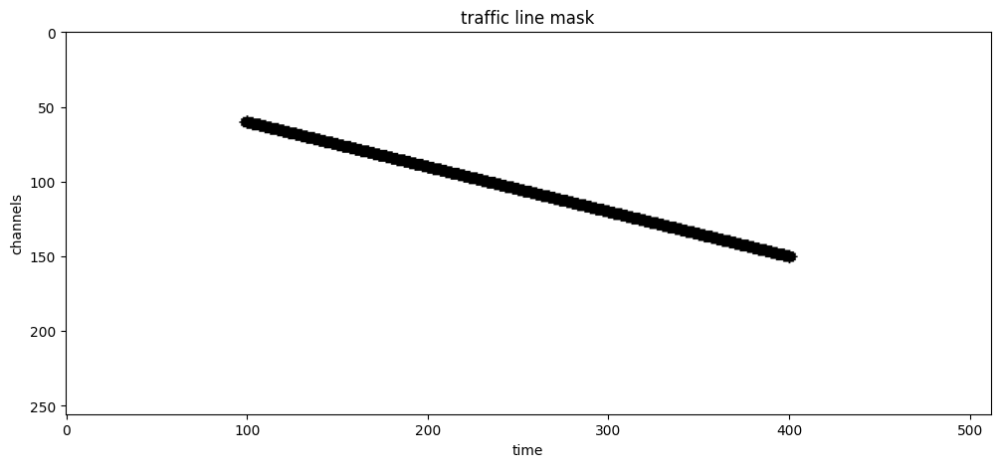

In [3]:
plt.figure(figsize=(12,5))
plt.imshow(mask.detach().cpu(), cmap="gray", aspect="auto")
plt.xlabel("time")
plt.ylabel("channels")
plt.title("traffic line mask")
plt.show()

In [5]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_traffic_e = [das_data/"train_1111.h5"]
test_files_traffic_e = [das_data/"test_1111.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_traffic_e = DasDataset(train_files_traffic_e)
test_set_traffic_e = DasDataset(test_files_traffic_e)
train_loader_traffic_e = DataLoader(train_set_traffic_e, batch_size=16, shuffle=True)
test_loader_traffic_e = DataLoader(test_set_traffic_e, batch_size=16, shuffle=False)

In [5]:
batch = next(iter(train_loader_traffic_e))
patch = batch [0:1].to(device)
print(patch.shape)

torch.Size([1, 1, 256, 512])


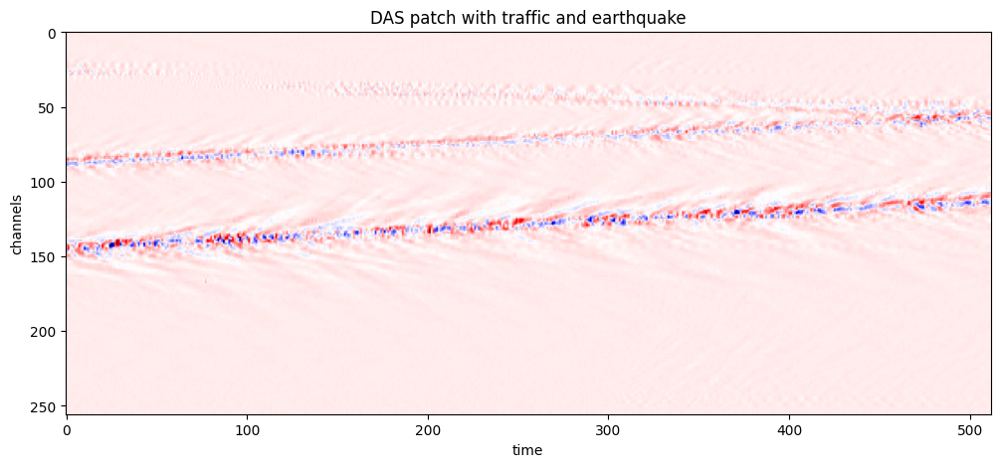

-18886.8203125 17503.234375


In [30]:
patch_denorm = denormalize(patch)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin, vmax = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with traffic and earthquake")
plt.show()
print(vmin, vmax)

In [ ]:
example_dir = Path("data/repaint_examples")
example_dir.mkdir(parents=True, exist_ok=True)
torch.save({"patch": patch.detach().cpu(),
            "desc": "Example for inpainting"},
            example_dir/"traffic_exp_01.pt")

In [6]:
example = torch.load("data/repaint_examples/traffic_exp_01.pt", map_location=device)
patch = example["patch"].to(device)
print(patch.shape)

torch.Size([1, 1, 256, 512])


In [7]:
import importlib
import utils.traffic_masks
importlib.reload(utils.traffic_masks)
from utils.traffic_masks import line_mask

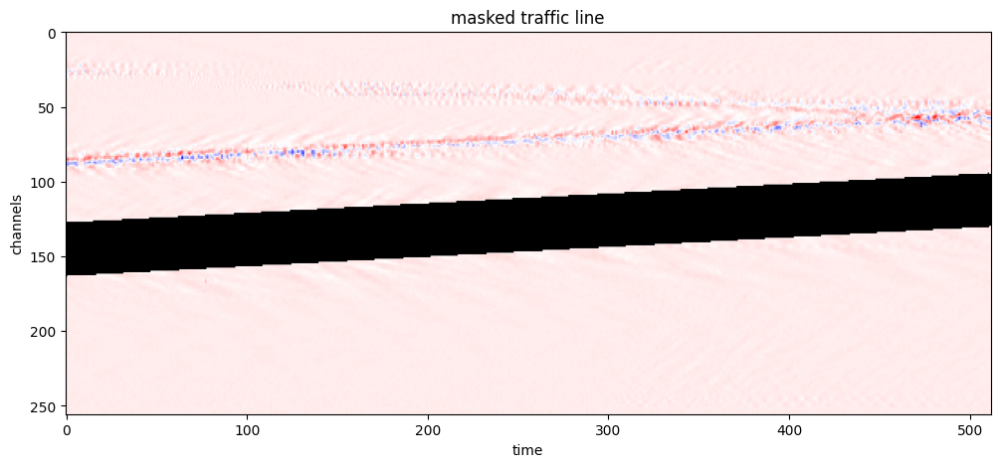

In [7]:
vmin = -18886.82
vmax = 17503.23
mask1  = line_mask(h=256, w=512, s=(0,145), e=(510,112), r=18, device=device)
mask1 = mask1.unsqueeze(0). unsqueeze(0)
missing_region = (mask1[0,0] == 0).detach().cpu()
masked_patch = patch * mask1
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin, vmax=vmax)
plt.imshow(missing_region, cmap="gray_r", aspect="auto", alpha = missing_region.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked traffic line")
plt.show()

In [8]:
def sample_repaint(model,scheduler,x0,mask,U=1, steps_to_save = [999,600,300,100,0]):
    with torch.no_grad():
        model.eval()
        B=x0.shape[0]
        T=scheduler.betas.shape[0]
        mask=mask.to(x0.device)
        xt=torch.rand_like(x0)
        snapshots = {}

        for step in reversed(range(T)):
            for u in range(U):
                t=torch.full((B,),step,device=x0.device,dtype=torch.long)
                predicted_noise=model(xt,t)
                xt_unknown,x0_pred=scheduler.reverse_sampling_step(xt,predicted_noise,step)
                if step>0:
                    gaussian_noise=torch.rand_like(x0)
                    t_prev=torch.full((B,),step-1,device=x0.device,dtype=torch.long)
                    x_known=scheduler.add_noise(x0,gaussian_noise,t_prev)
                else:
                    x_known=x0
                xt_prev=mask*x_known +(1.0-mask)*xt_unknown

                if(u == U-1) and (step in steps_to_save):
                    snapshots[step] = xt_prev.detach().clone()
                
                if(u<U-1) and (step>0):
                    z=torch.rand_like(xt_prev)
                    xt=torch.sqrt(scheduler.alphas[step]) * xt_prev +torch.sqrt(scheduler.betas[step])*z
                else: xt=xt_prev
        return xt, snapshots  

**WEIGHTED MAMBA 1.2/1.8**

In [9]:
from models.unet_mamba import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_mb=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_mb_path= Path(checkpoints)/"das_ddpm_earthquake_model_mamba_weighted_1.2_1.8.pth"
checkpoint_model_mb = torch.load(model_mb_path, map_location = device)
model_mb.load_state_dict(checkpoint_model_mb["model_mb"])

<All keys matched successfully>

In [12]:
scheduler_E = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)

In [11]:
model_mb.eval()
result, snapshots = sample_repaint(model=model_mb, scheduler=scheduler_E, x0= patch, mask=mask1,U=1, steps_to_save = [999,600,300,100,0])

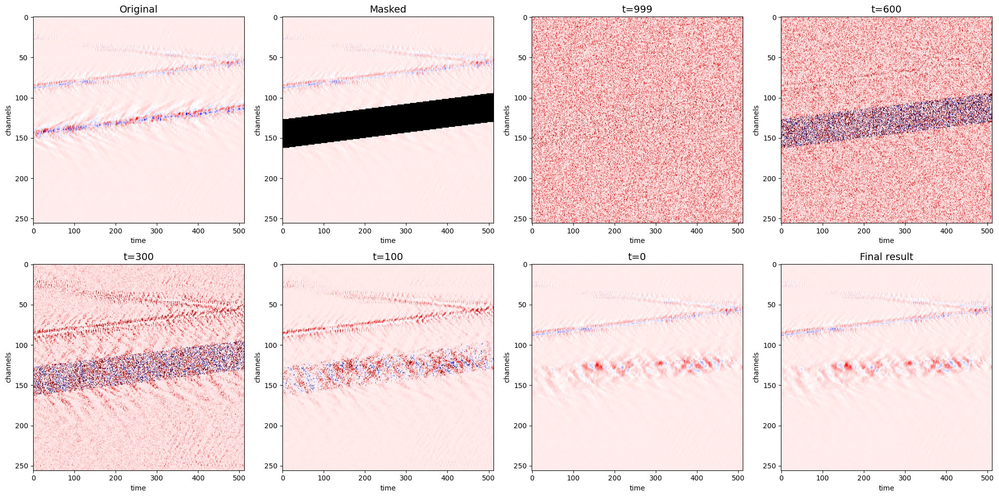

In [ ]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

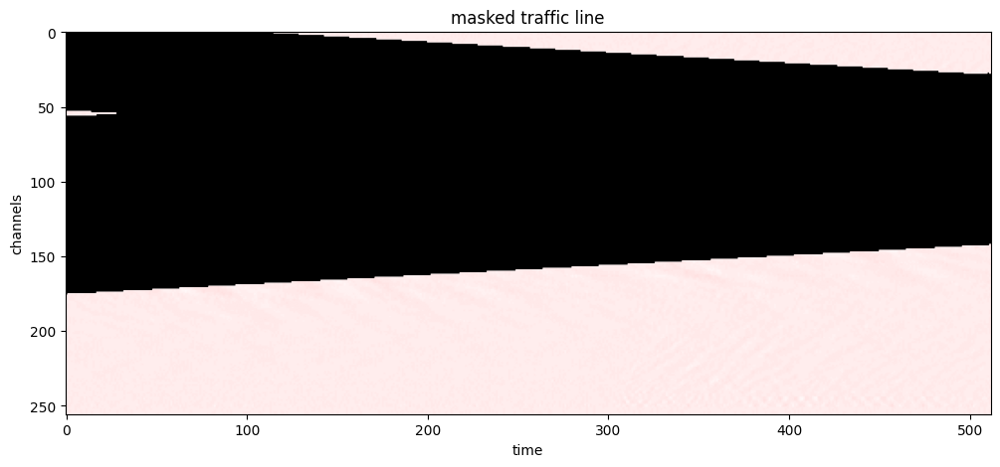

In [9]:
vmin = -18886.82
vmax = 17503.23
mask1  = line_mask(h=256, w=512, s=(0,145), e=(510,112), r=30, device=device)
mask2  = line_mask(h=256, w=512, s=(0,86), e=(510,57), r=30, device=device)
mask3  = line_mask(h=256, w=512, s=(0,22), e=(510,58), r=30, device=device)
mask_all = mask1*mask2*mask3
mask_all = mask_all.unsqueeze(0). unsqueeze(0)
missing_region = (mask_all[0,0] == 0).detach().cpu()
masked_patch = patch * mask_all
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin, vmax=vmax)
plt.imshow(missing_region, cmap="gray_r", aspect="auto", alpha = missing_region.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked traffic line")
plt.show()

In [15]:
result2, snapshots2 = sample_repaint(model=model_mb, scheduler=scheduler_E, x0= patch, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

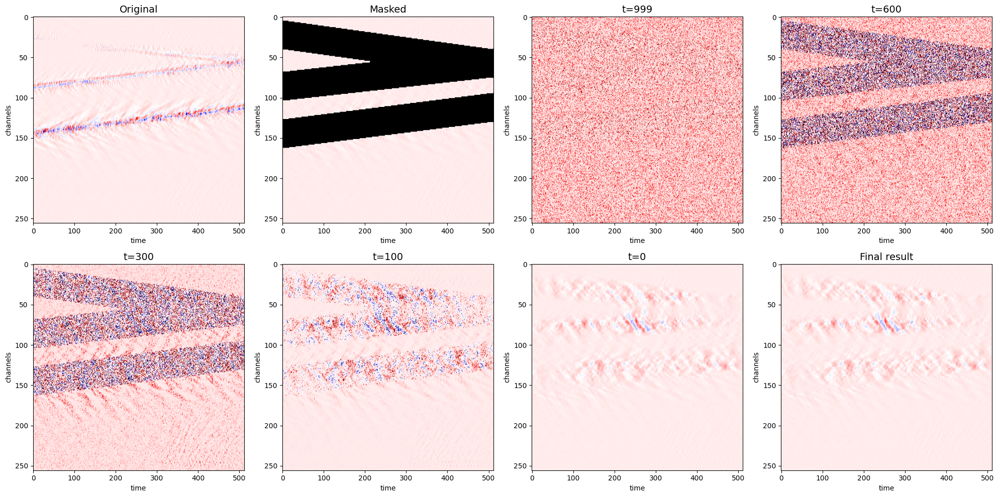

In [17]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result2)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots2[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

In [21]:
missing = mask_all == 0
result_denorm =  denormalize(result2)
generated_region = result_denorm[missing]
print("generated masked region")
print("median abs:", generated_region.abs().median().item())
print("std:", generated_region.std().item())
print("99%:", torch.quantile(generated_region.abs(), 0.99).item())
print("99.9%:", torch.quantile(generated_region.abs(), 0.999).item())

generated masked region
median abs: 235.52635192871094
std: 600.15673828125
99%: 2254.21630859375
99.9%: 3915.811767578125


**REGION WEIGHTED MAMBA**

In [23]:
from models.unet_mamba import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_mb2=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_mb2_path= Path(checkpoints)/"das_ddpm_earthquake_model_mamba_region_weighted_002_0006_coeff.pth"
checkpoint_model_mb2 = torch.load(model_mb2_path, map_location = device)
model_mb2.load_state_dict(checkpoint_model_mb2["model_mb"])

<All keys matched successfully>

In [24]:
result5, snapshots5 = sample_repaint(model=model_mb2, scheduler=scheduler_E, x0= patch, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

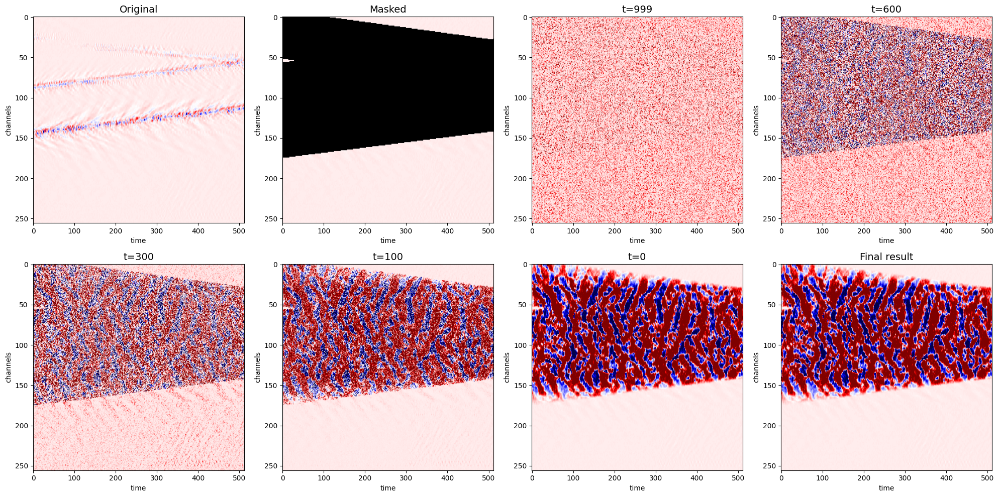

In [26]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result5)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots5[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**SPCII Model (not corrected)**

In [18]:
from models.unet_spcii import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_v2=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_v2_path = Path(checkpoints)/"das_ddpm_earthquake_model_spcii.pth"
checkpoint_model_v2 = torch.load(model_v2_path, map_location = device)
model_v2.load_state_dict(checkpoint_model_v2["model_earthquake_spcii"])

<All keys matched successfully>

In [19]:
mask_all=mask_all.to(device)
model_v2.eval()
result2, snapshots2 = sample_repaint(model=model_v2, scheduler=scheduler_E, x0= patch, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

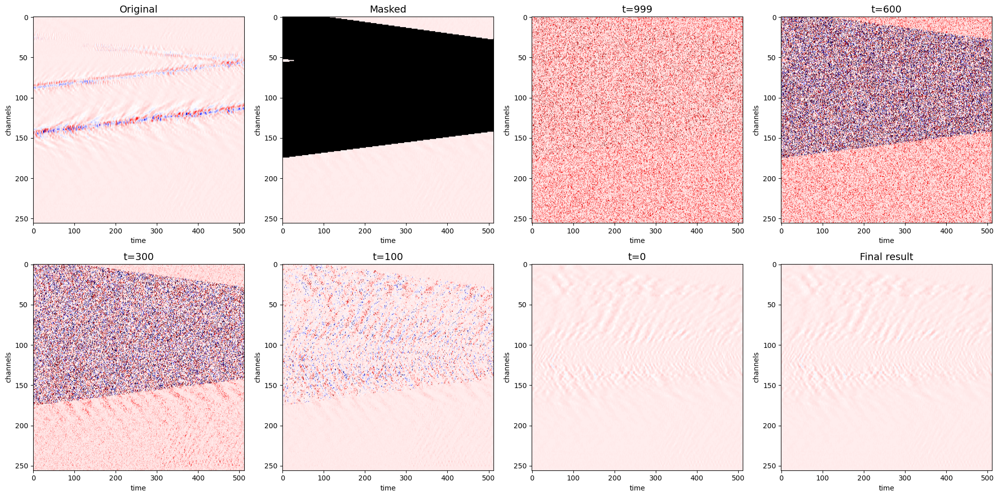

In [20]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result2)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots2[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

In [21]:
missing = mask_all == 0
result_denorm =  denormalize(result2)
generated_region = result_denorm[missing]
print("generated masked region")
print("median abs:", generated_region.abs().median().item())
print("std:", generated_region.std().item())
print("99%:", torch.quantile(generated_region.abs(), 0.99).item())
print("99.9%:", torch.quantile(generated_region.abs(), 0.999).item())

generated masked region
median abs: 144.10926818847656
std: 262.39990234375
99%: 827.0343627929688
99.9%: 1217.35986328125


**SPCII Model (corrected)**

In [10]:
from models.unet_spcii import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_v3=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_v3_path = Path(checkpoints)/"das_ddpm_earthquake_model_spcii2.pth"
checkpoint_model_v3 = torch.load(model_v3_path, map_location = device)
model_v3.load_state_dict(checkpoint_model_v3["model_earthquake_spcii"])

<All keys matched successfully>

In [13]:
result3, snapshots3 = sample_repaint(model=model_v3, scheduler=scheduler_E, x0= patch, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

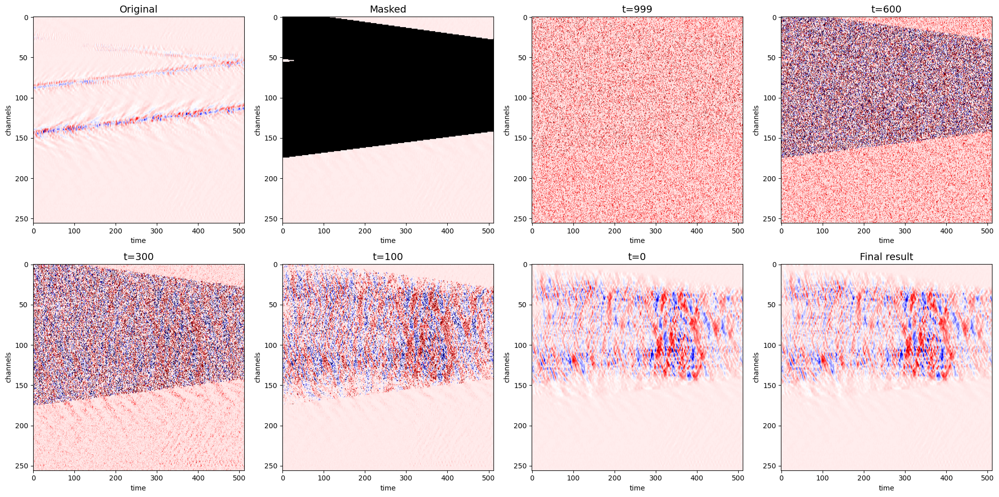

In [14]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result3)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots3[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**SSA MODEL**

In [19]:
from models.unet_ssa import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_v4=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_v4_path = Path(checkpoints)/"das_ddpm_earthquake_model_ssa.pth"
checkpoint_model_v4 = torch.load(model_v4_path, map_location = device)
model_v4.load_state_dict(checkpoint_model_v4["model_earthquake_ssa"])

<All keys matched successfully>

In [20]:
result4, snapshots4 = sample_repaint(model=model_v4, scheduler=scheduler_E, x0= patch, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

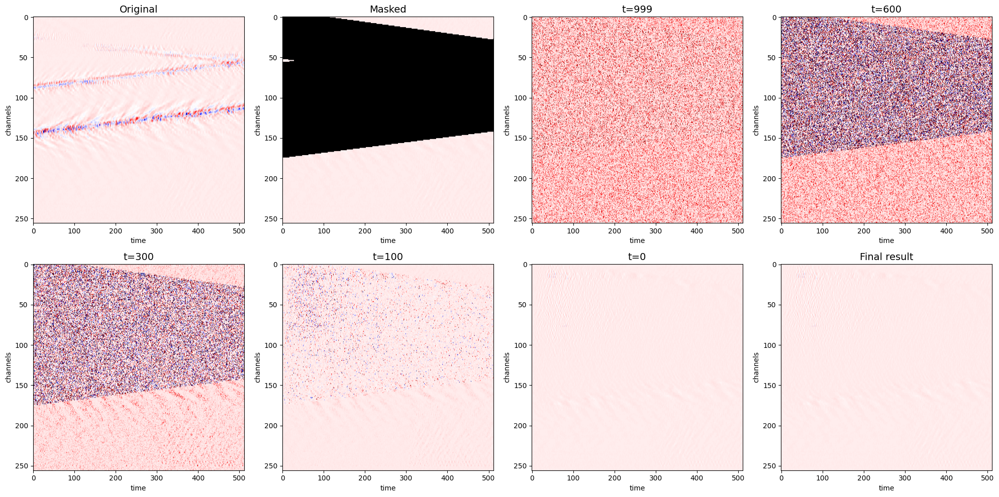

In [21]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result4)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots4[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()